In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print("Libraries imported successfully!")

Libraries imported successfully!


In [1]:

from google.colab import files
uploaded = files.upload()

Saving Sample - Superstore.csv to Sample - Superstore.csv


In [3]:
import io
import pandas as pd

filename = next(iter(uploaded))

try:
    df = pd.read_csv(io.BytesIO(uploaded[filename]), encoding="latin1")
    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)
    print("\nColumn names:")
    print(df.columns.tolist())
    display(df.head())

except Exception as e:
    print("Error:", e)

Dataset loaded successfully!
Dataset shape: (9994, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [6]:
#dateset cleaning
# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Dataset information
print("\nDataset information:")
df.info()

Missing values in each column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Number of duplicate rows:
0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7 

In [7]:
#data cleaning
# Create a copy of the dataset
df = df.copy()

# Remove duplicate rows
df = df.drop_duplicates()

# Display missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove rows where important values are missing
df = df.dropna(subset=["Order Date", "Sales"])

# Display results
print("\nDataset cleaned successfully!")
print("Remaining rows and columns:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Dataset cleaned successfully!
Remaining rows and columns: (9994, 21)

Missing values after cleaning:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [8]:
# conversion of order data
# Convert Order Date into datetime format
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

# Remove rows with invalid dates
df = df.dropna(subset=["Order Date"])

# Extract year and month
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month

# Create monthly sales data
monthly_sales = df.groupby(
    df["Order Date"].dt.to_period("M")
)["Sales"].sum().reset_index()

# Convert month to datetime format
monthly_sales["Order Date"] = monthly_sales["Order Date"].dt.to_timestamp()

print("Monthly sales calculated successfully!")
display(monthly_sales.head(10))

Monthly sales calculated successfully!


,Order Date,Sales
0,2014-01-01,14236.8950
1,2014-02-01,4519.8920
2,2014-03-01,55691.0090
3,2014-04-01,28295.3450
4,2014-05-01,23648.2870
5,2014-06-01,34595.1276
6,2014-07-01,33946.3930
7,2014-08-01,27909.4685
8,2014-09-01,81777.3508
9,2014-10-01,31453.3930


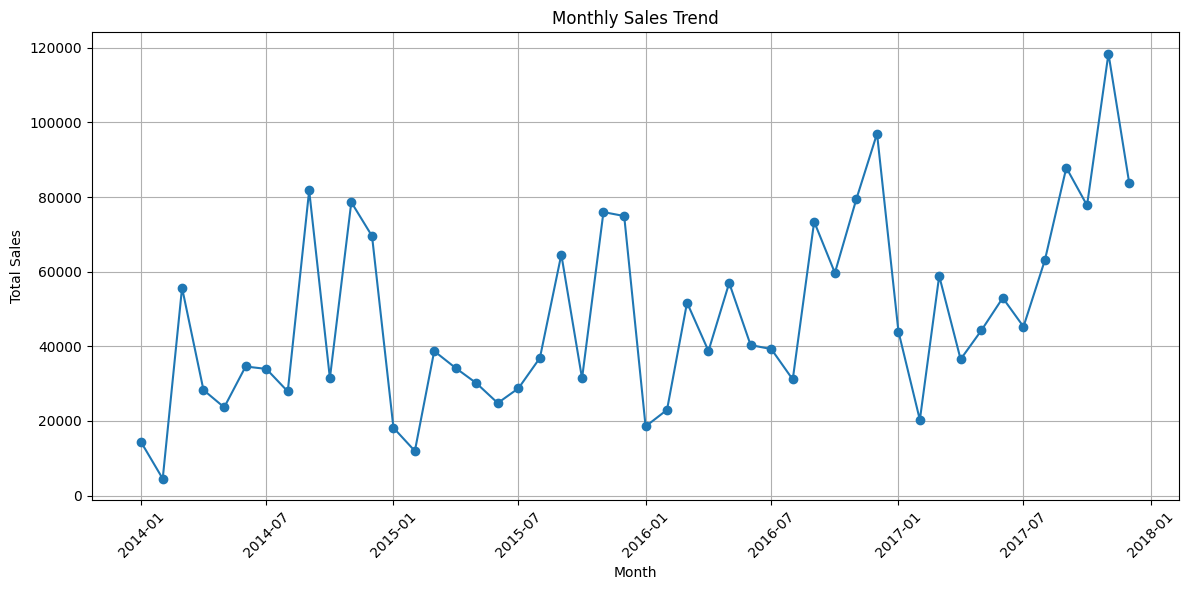

In [9]:
#sales graph
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["Order Date"],
    monthly_sales["Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [10]:
#forecasting model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Prepare features
monthly_sales["Time"] = np.arange(len(monthly_sales))

X = monthly_sales[["Time"]]
y = monthly_sales["Sales"]

# Split data chronologically
split_index = int(len(monthly_sales) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict test-period sales
y_pred = model.predict(X_test)

# Evaluate model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Model trained successfully!")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))


Model trained successfully!
Mean Absolute Error (MAE): 18041.64
Root Mean Squared Error (RMSE): 23416.38


In [11]:
#predict future sales
# Forecast the next 3 months
future_steps = 3

last_time = monthly_sales["Time"].max()

future_time = pd.DataFrame({
    "Time": range(last_time + 1, last_time + future_steps + 1)
})

future_predictions = model.predict(future_time)

# Create forecast dates
last_date = monthly_sales["Order Date"].max()

future_dates = pd.date_range(
    start=last_date + pd.offsets.MonthBegin(1),
    periods=future_steps,
    freq="MS"
)

# Create forecast dataframe
forecast_df = pd.DataFrame({
    "Month": future_dates,
    "Predicted Sales": future_predictions
})

print("Future Sales Forecast:")
display(forecast_df.round(2))

Future Sales Forecast:


,Month,Predicted Sales
0,2018-01-01,63485.52
1,2018-02-01,64185.07
2,2018-03-01,64884.62


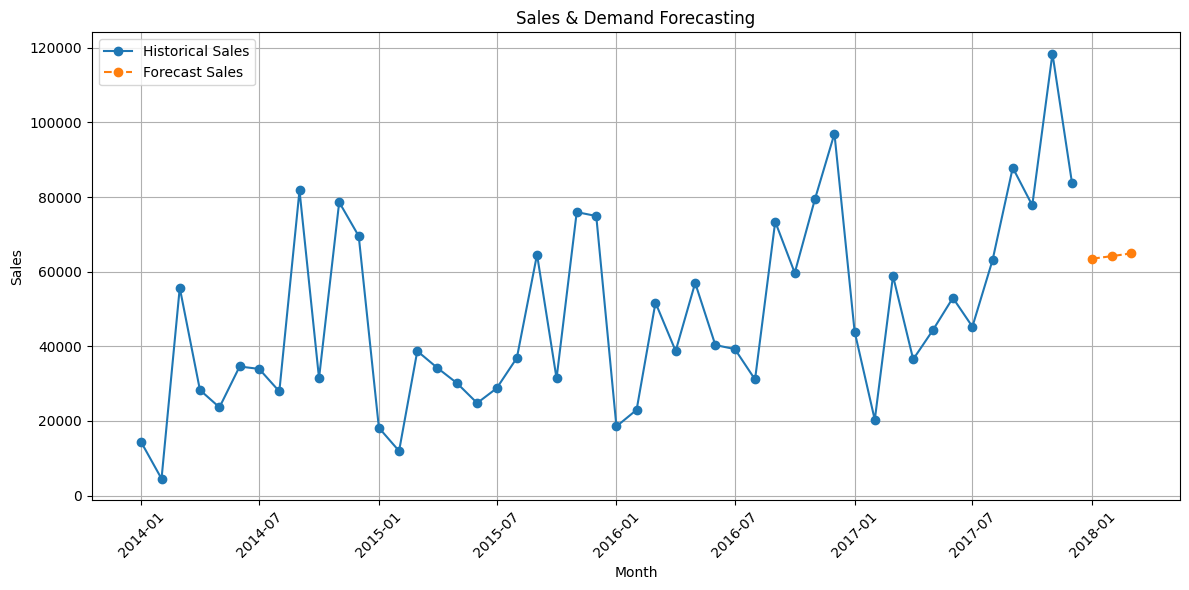

Forecast graph saved successfully!


In [12]:
#forecast visualization
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# Historical sales
plt.plot(
    monthly_sales["Order Date"],
    monthly_sales["Sales"],
    marker="o",
    label="Historical Sales"
)

# Future forecast
plt.plot(
    forecast_df["Month"],
    forecast_df["Predicted Sales"],
    marker="o",
    linestyle="--",
    label="Forecast Sales"
)

plt.title("Sales & Demand Forecasting")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("sales_forecast.png", dpi=300)
plt.show()

print("Forecast graph saved successfully!")


In [13]:
#save project files
import pandas as pd
import numpy as np

# 1. Save cleaned dataset
df.to_csv("cleaned_sales_data.csv", index=False)

# 2. Save monthly sales data
monthly_sales.to_csv("monthly_sales.csv", index=False)

# 3. Save future sales forecast
forecast_df.to_csv("future_sales_forecast.csv", index=False)

# 4. Save model evaluation results
evaluation = pd.DataFrame({
    "Metric": ["MAE", "RMSE"],
    "Value": [mae, rmse]
})

evaluation.to_csv("model_evaluation.csv", index=False)

print("All project output files saved successfully!")

print("\nFiles created:")
print("1. cleaned_sales_data.csv")
print("2. monthly_sales.csv")
print("3. future_sales_forecast.csv")
print("4. model_evaluation.csv")
print("5. sales_forecast.png")

All project output files saved successfully!

Files created:
1. cleaned_sales_data.csv
2. monthly_sales.csv
3. future_sales_forecast.csv
4. model_evaluation.csv
5. sales_forecast.png


In [16]:
import os
import zipfile
from google.colab import files

output_files = [
    "cleaned_sales_data.csv",
    "monthly_sales.csv",
    "future_sales_forecast.csv",
    "model_evaluation.csv",
    "sales_forecast.png"
]

zip_name = "Sales_Demand_Forecasting_Outputs.zip"

with zipfile.ZipFile(zip_name, "w") as zipf:
    for filename in output_files:
        if os.path.exists(filename):
            zipf.write(filename)
            print("Added:", filename)
        else:
            print("Not found:", filename)

print("\nZIP file created successfully!")

files.download(zip_name)

Added: cleaned_sales_data.csv
Added: monthly_sales.csv
Added: future_sales_forecast.csv
Added: model_evaluation.csv
Added: sales_forecast.png

ZIP file created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>